# Notebook 06 — Historical Landslide Multi-Trigger Analysis
**Malaysia Landslide Susceptibility Decision-Support Dashboard | Exploratory investigation only — rainfall compatibility, not causal attribution**

**Scope:** Audit historical source descriptions, retain multi-label reported triggers, link only verified event identifiers, compare *pre-event* environmental measurements, and flag compatibility for unknown-trigger records. **Does not train or change the existing susceptibility classifier**, inventory, pseudo-absences, folds or trained models.

**Interpretation safeguards:** (1) Reported triggers are not proven causes. (2) Missing triggers are unknown, not negative. (3) Event-level linkage requires an explicit unique identifier, not proximity. (4) Environmental compatibility is not causal attribution. (5) No event trigger or post-event feature may enter the primary binary susceptibility classifier. (6) Unmatched original source rows are retained separately, not silently assigned to processed events.

**Verified source schema (uploaded inventory snapshots, 23 November 2026):** COOLR `landslide_trigger` (236 rows, with `unknown` explicit); GFLD validated `Trigger_` (61 rows); JMG original **both** `Punca_Tana` and `Punca__` (52 rows; the second contributes 3 additional nonempty cause fields); JMG archive (366 rows) has **no reported trigger column**. `Jenis_Tana` / `Jenis Tanah Runtuh` are failure **types**, and `Geologi` is context, **not a reported trigger**. Source text such as `event_description`, `Report_1`, and `Catatan` is supporting material requiring separate manual review, never automatically labelled as an authoritative cause. Uploaded snapshots may contain duplicate *physical events* across sources: raw counts cannot be summed as unique landslides.

**Before running:** Place the notebook in `notebooks/` of your FYP repository. Review `SOURCE_OVERRIDE`, `MANUAL_ID_CROSSWALK`, and `TRIGGER_OVERRIDE` in section 0. Unlike the original pipelines, this notebook is read-only outside its dedicated output folder.

**2026-11-23 refinement:** adds auditable crosswalk diagnostics, exact event/control date checks, and independent pre-event rainfall provenance review. No raw/processed modelling files are modified.

## 0. Configuration and reproducibility
Discover project paths from the existing Notebook 02/03 directory layout. Every data input is read-only; outputs go exclusively to `outputs/historical_trigger_analysis/`.

In [1]:
from pathlib import Path
import re, json, hashlib, unicodedata, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p/'data'/'processed'/'inventory').is_dir()),None)
if ROOT is None: raise FileNotFoundError('Open notebook from the Landslide_FYP project, containing data/processed/inventory/')
INVENTORY=ROOT/'data/processed/inventory/event_candidates.csv'
FEATURES=ROOT/'data/processed/features/environmental_features.csv'
STATIC=ROOT/'data/processed/modelling/static_model_dataset.csv'
TEMPORAL=ROOT/'data/processed/modelling/temporal_model_dataset.csv'
ENHANCEMENT=ROOT/'data/processed/features/historical_environmental_enhancement_recovery_REVIEW.csv'
if not ENHANCEMENT.exists(): ENHANCEMENT=ROOT/'data/processed/features/historical_environmental_enhancement.csv'
OUT=ROOT/'outputs/historical_trigger_analysis'; FIG=OUT/'figures'; FIG.mkdir(parents=True,exist_ok=True)
# Explicit path/column overrides are preferred when automated discovery is ambiguous.
SOURCE_OVERRIDE={'COOLR':None,'GFLD':None,'JMG_original':None,'JMG_archive':None}
TRIGGER_OVERRIDE={'COOLR':['landslide_trigger'], 'GFLD':['Trigger_'], 'JMG_original':['Punca_Tana','Punca__'], 'JMG_archive':[]}  # Verified against uploaded source schemas
MANUAL_ID_CROSSWALK=None  # Optional analyst-verified CSV with source, source_record_id, event_candidate_id; or source, row_index, event_candidate_id for archives without stable row IDs
# Do NOT infer identity from nearest coordinates or sequential row order.
SOURCE_PATTERNS={'COOLR':('coolr_malaysia_candidates','coolr','nasa_coolr'),'GFLD':('gfld_malaysia_validated',),
                 'JMG_original':('jmg_government_raw_landslide_inventory','jmg_original','original_jmg'),
                 'JMG_archive':('jmg_archive_2021_2022_raw','archive_2021_2022')}
REJECT_FILENAME=('checkpoint','audit','summary','matched','model_dataset','background','output','backup')  # 'candidates' is part of actual COOLR source name
pd.set_option('display.max_columns',45)
print('ROOT:',ROOT,'\nOUTPUT:',OUT)
for label,p in [('inventory',INVENTORY),('environmental',FEATURES),('static',STATIC),('temporal',TEMPORAL),('enhancement',ENHANCEMENT)]:print(label,p.exists(),p)
if not INVENTORY.exists():raise FileNotFoundError(f'Run Notebook 01 first: {INVENTORY}')

ROOT: C:\landslide_fyp 
OUTPUT: C:\landslide_fyp\outputs\historical_trigger_analysis
inventory True C:\landslide_fyp\data\processed\inventory\event_candidates.csv
environmental True C:\landslide_fyp\data\processed\features\environmental_features.csv
static True C:\landslide_fyp\data\processed\modelling\static_model_dataset.csv
temporal True C:\landslide_fyp\data\processed\modelling\temporal_model_dataset.csv
enhancement True C:\landslide_fyp\data\processed\features\historical_environmental_enhancement_recovery_REVIEW.csv


## 1. Inventory provenance, source discovery and data-quality audit
The latest *processed event candidates* are the authoritative universe for this investigation. These may include records that were not eligible for the final static or temporal modelling cohorts; report that distinction explicitly. A processed candidate is not automatically a unique physical landslide if original deduplication was provisional.

Raw-file discovery is **conservative** and reports ambiguity. Raw totals represent source-file rows; they must never be summed to claim unique events.
**GFLD duplicate file handling:** If both `gfld_malaysia_validated.csv` and `gfld_malaysia_validated.geojson` exist, only the validated CSV is selected. This avoids double-counting equivalent records. The source-discovery audit still lists every candidate file.

In [2]:
def read_any(p):
    if p.suffix.lower()=='.csv': return pd.read_csv(p,low_memory=False)
    if p.suffix.lower() in ('.xlsx','.xls'): return pd.read_excel(p)
    if p.suffix.lower() in ('.geojson','.json'):
        doc=json.loads(p.read_text(encoding='utf-8'))
        if doc.get('type')!='FeatureCollection': raise ValueError('Expected GeoJSON FeatureCollection: '+str(p))
        return pd.DataFrame([f.get('properties') or {} for f in doc['features']])
    raise ValueError('Unsupported table '+str(p))
def norm(s):return re.sub(r'[^a-z0-9]+','_',unicodedata.normalize('NFKD',str(s)).lower()).strip('_')
def pick(df, candidates):
    d={norm(c):c for c in df.columns}
    return next((d[norm(x)] for x in candidates if norm(x) in d),None)
def discover_source(src):
    override=SOURCE_OVERRIDE[src]
    if override:
        p=Path(override);p=p if p.is_absolute() else ROOT/p
        if not p.exists():raise FileNotFoundError(p)
        return p,[str(p)]
    bases=[ROOT/'data/raw/inventory',ROOT/'data/raw',ROOT/'data/processed/inventory']
    matches={}
    for base in bases:
        if base.exists():
            for ext in ('*.csv','*.geojson','*.xlsx'):
                for p in base.rglob(ext):
                    low=p.name.lower()
                    if any(t in low for t in SOURCE_PATTERNS[src]) and not any(t in low for t in REJECT_FILENAME):
                        matches[str(p.resolve())]=p
    found=sorted(matches.values(),key=lambda x:str(x))
    if src=='GFLD' and len(found)>1:
        validated_csv=[p for p in found if p.name.lower()=='gfld_malaysia_validated.csv']
        if len(validated_csv)==1:
            return validated_csv[0],[str(p) for p in found]
        # Same inventory in CSV and GeoJSON is one source, not two events.
        validated_csv=[p for p in found if p.name.lower().startswith('gfld_malaysia_validated') and p.suffix.lower()=='.csv']
        if len(validated_csv)==1:
            return validated_csv[0],[str(p) for p in found]
    return (found[0] if len(found)==1 else None),[str(p) for p in found]
inv=pd.read_csv(INVENTORY,low_memory=False)
assert 'event_candidate_id' in inv and inv.event_candidate_id.notna().all() and inv.event_candidate_id.is_unique,'Processed event IDs must be unique'
assert 'source' in inv,'Processed inventory missing source'
inv['event_candidate_id']=inv.event_candidate_id.astype(str)
source_raw={};files_audit=[]
for src in SOURCE_PATTERNS:
    f,candidates=discover_source(src)
    rec={'source':src,'selected_path':str(f) if f else '', 'candidates_found':len(candidates),'candidate_paths':' | '.join(candidates),'status':'OK' if f else ('AMBIGUOUS_SET_OVERRIDE' if candidates else 'NOT_FOUND')}
    if f:
        try:source_raw[src]=read_any(f);rec['raw_rows']=len(source_raw[src]);rec['columns']=' | '.join(map(str,source_raw[src].columns))
        except Exception as exc:rec['status']='READ_FAILED';rec['error']=str(exc)
    files_audit.append(rec)
file_audit=pd.DataFrame(files_audit)
display(file_audit[['source','status','raw_rows','selected_path']] if 'raw_rows' in file_audit else file_audit)
file_audit.to_csv(OUT/'01_source_file_discovery.csv',index=False)
print('Processed candidate rows:',len(inv),'| by source:');display(inv.source.value_counts(dropna=False).rename_axis('processed_source').reset_index(name='rows'))
print('Inventory columns:',inv.columns.tolist())
print('If a source is missing or ambiguous, provide its relative path in SOURCE_OVERRIDE and rerun.')

,source,status,raw_rows,selected_path
0,COOLR,OK,236,C:\landslide_fyp\data\raw\inventory\NASA_COOLR...
1,GFLD,OK,61,C:\landslide_fyp\data\raw\inventory\GFLD\gfld_...
2,JMG_original,OK,52,C:\landslide_fyp\data\raw\inventory\JMG\JMG_Go...
3,JMG_archive,OK,366,C:\landslide_fyp\data\raw\inventory\JMG_Archiv...


Processed candidate rows: 713 | by source:


,processed_source,rows
0,JMG_archive,364
1,COOLR,236
2,GFLD,61
3,JMG_original,52


Inventory columns: ['record_uid', 'source', 'source_row', 'source_identifier', 'original_date_value', 'event_date', 'date_precision', 'reported_year', 'state_raw', 'district_raw', 'location_raw', 'longitude_candidate', 'latitude_candidate', 'projected_x_raw', 'projected_y_raw', 'coordinate_status', 'coordinate_method', 'coordinate_crs', 'source_geometry_match_m', 'native_source_file', 'quality_flags', 'flag_count', 'jmg_original_control_uid', 'jmg_raw_control_distance_m', 'jmg_wgs_control_distance_m', 'jmg_control_check_status', 'malaysia_polygon_status', 'geographic_verification_level', 'geographic_review_required', 'coordinate_usable_for_preliminary_spatial_review', 'duplicate_candidate_links', 'duplicate_review_status', 'state_standard', 'district_standard', 'location_standard', 'exact_row_representative_uid', 'exact_repeated_copy', 'candidate_pair_flag', 'archive_crs_evidence_level', 'archive_crs_hypothesis', 'strong_cross_source_duplicate_candidate', 'archive_matches_original_cont

## 2. Identify source triggers and establish safe event-level mappings
A raw source row can be linked to an event **only** if it already contains the exact curated `event_candidate_id`, or has an *explicitly verified* crosswalk. Source-native IDs are not assumed interchangeable with curated IDs. Raw rows that cannot be matched remain in the raw audit; trigger content is never transferred by nearest-coordinate heuristics.

If your Notebook 01 generated a native-to-curated ID mapping, export its checked table to a three-column `source`, `source_record_id`, `event_candidate_id` CSV and set `MANUAL_ID_CROSSWALK`.

**Actual field mapping, verified from uploaded files:**

| Source | Trigger fields | Record key candidate | Event date | Notes |
|---|---|---|---|---|
| COOLR | `landslide_trigger` | `event_id`, `objectid` | `event_date` (epoch milliseconds) | `unknown`/`other` are not confirmed causes; descriptions are separate reporting context |
| GFLD validated | `Trigger_` | `LandslideN`, `FID` | `Date` (epoch milliseconds), `Year` | `mining (unknown)` needs manual interpretation |
| JMG original | **`Punca_Tana` and `Punca__`** | `ID_Tanah_R` (partially missing), `SOURCE_FILE` | `Hari` + `Bulan` + `Tahun` (Malay month names) | `Geologi` is geology, `Jenis_Tana` is landslide type, not trigger text |
| JMG archive | **No trigger column** | No stable unique event ID in uploaded CSV | `Tarikh` (day-first) | `Jenis Tanah Runtuh` is type, never a cause; do not infer causes from it |

The source-native identifiers above **must not** be assumed equal to the processed `event_candidate_id`. Link with an independently verified crosswalk if the processed inventory has no direct matching key.


In [3]:
TRIGGER_COL_NAMES=['trigger','triggers','trigger_type','triggering_factor','triggering_factors','trigger_description','reported_trigger','landslide_trigger','cause','causes','cause_of_landslide','landslide_cause','punca','punca_tana','punca__','punca_kejadian','faktor_penyebab','faktor','penyebab','sebab']
EVENT_ID_NAMES=['event_candidate_id','curated_event_id']
RAW_ID_NAMES=['source_record_id','record_id','event_id','landslide_id','id','objectid','fid','id_tanah_r','landsliden']
DATE_NAMES=['event_date','date','eventdate','date','landslide_date','occurrence_date','tarikh','tarikh_kejadian']
LAT_NAMES=['latitude','latitude_candidate','lat','y']; LON_NAMES=['longitude','longitude_candidate','lon','long','x']
AREA_NAMES=['state','negeri','district','daerah','location','lokasi']

def trigger_columns(d,source):
    if source in TRIGGER_OVERRIDE:
        values=TRIGGER_OVERRIDE[source]
        absent=[v for v in values if v not in d.columns]
        if absent: raise KeyError(f'{source} expected trigger columns missing: {absent}')
        return values
    return [c for c in d if norm(c) in {norm(t) for t in TRIGGER_COL_NAMES}]
all_sources={'PROCESSED':inv,**source_raw}
schema=[]
for name,d in all_sources.items():
    schema.append({'source':name,'rows':len(d),'trigger_columns':' | '.join(trigger_columns(d,name)),
      'curated_id_col':pick(d,EVENT_ID_NAMES),'raw_id_col':pick(d,RAW_ID_NAMES),
      'date_col':pick(d,DATE_NAMES),'lon_col':pick(d,LON_NAMES),'lat_col':pick(d,LAT_NAMES),
      'area_col':pick(d,AREA_NAMES)})
schema_df=pd.DataFrame(schema);display(schema_df);schema_df.to_csv(OUT/'02_raw_and_processed_schema_audit.csv',index=False)
# Optional exact-UID crosswalk: only accept a raw identifier if it ALREADY equals
# a preserved curated UID with consistent source and unique identity. Never guess
# that source row 1 equals record_uid :00001 without an auditable origin mapping.
# An external, inspected Notebook-01 crosswalk may be supplied using the configuration above.
if MANUAL_ID_CROSSWALK:
    crossfile=Path(MANUAL_ID_CROSSWALK)
    if not crossfile.is_absolute(): crossfile=ROOT/crossfile
    cross=pd.read_csv(crossfile,dtype=str)
    assert {'source','event_candidate_id'}.issubset(cross),'Crosswalk needs source and event_candidate_id'
    assert ('source_record_id' in cross or 'row_index' in cross),'Crosswalk requires verified source_record_id or row_index'
    if 'source_record_id' in cross: cross['source_record_id']=cross.source_record_id.astype('string')
    if 'row_index' in cross: cross['row_index']=cross.row_index.astype('string')
    assert cross.event_candidate_id.isin(inv.event_candidate_id).all(),'Crosswalk points outside processed event universe'
else: cross=pd.DataFrame(columns=['source','source_record_id','row_index','event_candidate_id'])

def make_text(df,cols):
    if not cols:return pd.Series('',index=df.index,dtype='object')
    return df[cols].fillna('').astype(str).apply(lambda r:' | '.join(x.strip() for x in r if x.strip() and x.strip().lower() not in ('nan','none','null','unknown','n/a','-')),axis=1)
raw_long=[]
for src,d in source_raw.items():
    cols=trigger_columns(d,src)
    x=pd.DataFrame({'source':src,'row_index':np.arange(len(d)), 'original_trigger_text':make_text(d,cols)})
    eid=pick(d,EVENT_ID_NAMES);rid=pick(d,RAW_ID_NAMES)
    x['source_record_id']=d[rid].astype('string').values if rid else pd.Series(pd.NA,index=x.index,dtype='string')
    x['source_native_id_column']=rid or ''
    x['trigger_field_names']=' | '.join(cols)
    x['raw_event_date']=d[pick(d,DATE_NAMES)].astype('string').values if pick(d,DATE_NAMES) else pd.NA
    x['raw_state']=d[pick(d,['Negeri','state','state_standard','admin_division_name'])].astype('string').values if pick(d,['Negeri','state','state_standard','admin_division_name']) else pd.NA
    x['event_candidate_id']=pd.Series(pd.NA,index=x.index,dtype='string')
    x['mapping_method']='UNMATCHED'
    if eid:
        ids=d[eid].astype('string')
        good=ids.isin(inv.event_candidate_id)&~ids.duplicated(keep=False)
        x.loc[good,'event_candidate_id']=ids[good].to_numpy();x.loc[good,'mapping_method']='DIRECT_UNIQUE_CURATED_ID'
    if not cross.empty:
        cc=cross.loc[cross.source.eq(src)].copy()
        if not cc.empty:
            # Prefer native ID where a stable native key exists; otherwise a verified source-row crosswalk.
            if 'source_record_id' in cc and cc.source_record_id.notna().any() and rid:
                cc=cc.loc[cc.source_record_id.notna(),['source_record_id','event_candidate_id']]
                assert not cc.source_record_id.duplicated().any(),f'Duplicate native IDs in crosswalk for {src}'
                assert not x.source_record_id.dropna().duplicated().any(),f'Nonunique source IDs for {src}: use an audited row_index crosswalk instead'
                mapper=cc.set_index('source_record_id').event_candidate_id
                mapped=x.source_record_id.map(mapper)
                method='VERIFIED_NATIVE_ID_CROSSWALK'
            elif 'row_index' in cc and cc.row_index.notna().any():
                cc=cc.loc[cc.row_index.notna(),['row_index','event_candidate_id']]
                assert not cc.row_index.duplicated().any(),f'Duplicate source row_index in crosswalk for {src}'
                mapper=cc.set_index('row_index').event_candidate_id
                mapped=x.row_index.astype(str).map(mapper)
                method='VERIFIED_ROW_INDEX_CROSSWALK'
            else:
                mapped=pd.Series(pd.NA,index=x.index);method='UNMATCHED'
            conflict=mapped.notna()&x.event_candidate_id.notna()&mapped.ne(x.event_candidate_id)
            assert not conflict.any(),f'Crosswalk contradicts direct curated IDs in {src}'
            use=mapped.notna()&x.event_candidate_id.isna()
            x.loc[use,'event_candidate_id']=mapped[use].values;x.loc[use,'mapping_method']=method
    duplicate=x.event_candidate_id.notna() & x.event_candidate_id.duplicated(keep=False)
    x.loc[duplicate,'mapping_method']='AMBIGUOUS_DUPLICATE_EVENT_ID';x.loc[duplicate,'event_candidate_id']=pd.NA
    raw_long.append(x)
raw=pd.concat(raw_long,ignore_index=True) if raw_long else pd.DataFrame(columns=['source','row_index','source_record_id','event_candidate_id','mapping_method','original_trigger_text'])
# Processed trigger text is authoritative when present; known raw descriptions are supplemental, never overwrite.
processed_text=make_text(inv,trigger_columns(inv,'PROCESSED'))
master=inv[['event_candidate_id','source']].copy();master['processed_trigger_text']=processed_text.values
if 'event_date' in inv:master['event_date']=inv.event_date.values
for f in ['date_precision','longitude_candidate','latitude_candidate','state','district','static_candidate','temporal_candidate']:
    if f in inv:master[f]=inv[f].values
valid_raw=raw[raw.event_candidate_id.notna() & raw.original_trigger_text.ne('')].copy()
aggregated=valid_raw.groupby('event_candidate_id').agg(raw_trigger_text=('original_trigger_text',lambda s:' | '.join(sorted(set(s)))),raw_trigger_sources=('source',lambda s:' | '.join(sorted(set(s))))).reset_index()
master=master.merge(aggregated,on='event_candidate_id',how='left',validate='one_to_one')
master['original_trigger_text']=master.processed_trigger_text.where(master.processed_trigger_text.ne('') & ~master.processed_trigger_text.str.lower().isin(['unknown','other','n/a','-']),master.raw_trigger_text.fillna(master.processed_trigger_text))
master['reported_text_provenance']=np.select([master.processed_trigger_text.ne(''),master.raw_trigger_text.notna()],['PROCESSED','LINKED_RAW'],default='UNAVAILABLE')
raw['reported_text_present']=raw.original_trigger_text.ne('')  # definitive availability recalculated after classification in Section 3
print('Raw records with verified links:',int(raw.event_candidate_id.notna().sum()),'/',len(raw))
print('Processed candidates with reported trigger text:',int(master.original_trigger_text.ne('').sum()),'/',len(master))
raw.to_csv(OUT/'03_raw_trigger_matching_audit.csv',index=False)
# Row counts by source are raw-file totals, not deduplicated cases.
audit=raw.groupby('source',dropna=False).agg(raw_records=('row_index','size'),raw_with_reported_trigger=('reported_text_present','sum'),verified_linked_rows=('event_candidate_id','count')).reset_index() if len(raw) else pd.DataFrame(columns=['source','raw_records','raw_with_reported_trigger','verified_linked_rows'])
audit['raw_missing_or_blank_only']=audit.raw_records-audit.raw_with_reported_trigger
audit['raw_nonblank_text_pct']=np.where(audit.raw_records.gt(0),100*audit.raw_with_reported_trigger/audit.raw_records,np.nan)
processed_counts=master.groupby('source',dropna=False).agg(processed_candidates=('event_candidate_id','size'),processed_with_reported_trigger=('original_trigger_text',lambda s:s.ne('').sum())).reset_index().rename(columns={'source':'processed_source'})
print('PRELIMINARY raw nonblank audit (includes explicit unknown; final corrected in Section 3):');display(audit);display(processed_counts)
audit.to_csv(OUT/'04_preliminary_text_presence_UNCLASSIFIED.csv',index=False);processed_counts.to_csv(OUT/'05_processed_source_trigger_availability.csv',index=False)

,source,rows,trigger_columns,curated_id_col,raw_id_col,date_col,lon_col,lat_col,area_col
0,PROCESSED,713,,event_candidate_id,NaN,event_date,longitude_candidate,latitude_candidate,NaN
1,COOLR,236,landslide_trigger,NaN,event_id,event_date,longitude,latitude,NaN
2,GFLD,61,Trigger_,NaN,FID,Date,longitude,latitude,NaN
3,JMG_original,52,Punca_Tana | Punca__,NaN,ID__,NaN,NaN,NaN,Negeri
4,JMG_archive,366,,NaN,NaN,Tarikh,NaN,NaN,Negeri


Raw records with verified links: 0 / 715
Processed candidates with reported trigger text: 0 / 713
PRELIMINARY raw nonblank audit (includes explicit unknown; final corrected in Section 3):


,source,raw_records,raw_with_reported_trigger,verified_linked_rows,raw_missing_or_blank_only,raw_nonblank_text_pct
0,COOLR,236,215,0,21,91.101695
1,GFLD,61,59,0,2,96.721311
2,JMG_archive,366,0,0,366,0.000000
3,JMG_original,52,47,0,5,90.384615


,processed_source,processed_candidates,processed_with_reported_trigger
0,COOLR,236,0
1,GFLD,61,0
2,JMG_archive,364,0
3,JMG_original,52,0


### 2A. Audit why raw trigger records are unmatched — no invented crosswalk
This section inspects the actual curated/source-native identifiers, duplicate keys and possible provenance columns. It exports an **unresolved crosswalk worksheet**, not an automatic coordinate join. Only populate `MANUAL_ID_CROSSWALK` in Section 0 after establishing row lineage from Notebook 01. A matching name, nearby coordinate or sequential suffix alone is insufficient evidence.

In [4]:
# Diagnostics only; intentionally does NOT fill event_candidate_id or alter the matching result.
LINKAGE_ID_HINTS = ['original_event_id','original_id','raw_event_id','source_event_id',
                    'source_record_id','record_uid','record_id','event_id','landslide_id',
                    'id_tanah_r','landsliden','fid','objectid','original_row_index',
                    'source_row_index','source_file','source_dataset','source_index']
linkage_schema=[]
for src,d in [('PROCESSED',inv),*source_raw.items()]:
    likely=[c for c in d.columns if norm(c) in {norm(k) for k in LINKAGE_ID_HINTS}
            or any(t in norm(c) for t in ('original','provenance','source_row','record_uid'))]
    for c in likely:
        values=d[c].astype('string').str.strip().replace('',pd.NA)
        linkage_schema.append(dict(source=src,column=c,total=len(values),nonmissing=int(values.notna().sum()),
                                   distinct_nonmissing=int(values.nunique(dropna=True)),
                                   duplicate_nonmissing=int(values[values.notna()].duplicated(keep=False).sum()),
                                   examples=' | '.join(values.dropna().head(4).astype(str))))
linkage_schema=pd.DataFrame(linkage_schema,columns=['source','column','total','nonmissing','distinct_nonmissing','duplicate_nonmissing','examples'])
linkage_schema.to_csv(OUT/'25_linkage_identifier_provenance_audit.csv',index=False)
display(linkage_schema)
raw_unresolved=raw.loc[raw.event_candidate_id.isna(),['source','row_index','source_record_id','source_native_id_column',
                                                       'original_trigger_text','mapping_method']].copy()
raw_unresolved['verified_event_candidate_id']=''
raw_unresolved['lineage_evidence']=''
raw_unresolved['resolution']='UNVERIFIED_NO_AUTOMATIC_LINK'
raw_unresolved.to_csv(OUT/'26_unresolved_crosswalk_review_WORKSHEET.csv',index=False)
print('Unresolved source rows:',len(raw_unresolved))
print('The review worksheet is NOT an approved crosswalk. Verify source IDs against Notebook 01 lineage and dedup decisions before applying.')

,source,column,total,nonmissing,distinct_nonmissing,duplicate_nonmissing,examples
0,PROCESSED,record_uid,713,713,713,0,JMG_original:00001 | JMG_original:00002 | JMG_...
1,PROCESSED,source_row,713,713,366,581,1 | 2 | 3 | 4
2,PROCESSED,original_date_value,713,713,330,429,18.0/Disember/2021.0 | 18.0/Disember/2021.0 | ...
3,PROCESSED,jmg_original_control_uid,713,46,46,0,JMG_original:00029 | JMG_original:00030 | JMG_...
4,PROCESSED,archive_matches_original_control,713,713,2,713,False | False | False | False
5,PROCESSED,source_record_uid,713,713,713,0,JMG_original:00001 | JMG_original:00002 | JMG_...
6,COOLR,objectid,236,236,236,0,23 | 82 | 154 | 172
7,COOLR,event_id,236,236,236,0,9083 | 2510 | 5500 | 5120
8,GFLD,FID,61,61,61,0,1013 | 1014 | 1015 | 1016
9,GFLD,LandslideN,61,61,61,0,5388 | 212 | 3464 | 4624


Unresolved source rows: 715
The review worksheet is NOT an approved crosswalk. Verify source IDs against Notebook 01 lineage and dedup decisions before applying.


### 2B. Source-row lineage candidate audit (not an automatic identity join)
The processed inventory preserves `source_row` and `source_record_uid`. Compare those with raw files **only as potential links**, after checking how Notebook 01 populated `source_row`. A source-row match is flagged as **UNVERIFIED** until original input ordering/lineage, duplicate removal and key fields are confirmed. This section never overwrites `master` or the raw reported triggers and never silently converts candidates to verified matches.

In [5]:
candidate_rows=[]
for src,d in source_raw.items():
    cur=inv.loc[inv.source.astype(str).eq(src)].copy()
    if not len(cur) or 'source_row' not in cur:
        candidate_rows.append({'source':src,'raw_row_index':pd.NA,'candidate_event_id':'',
                               'status':'NO_PROCESSED_SOURCE_ROW','validation_evidence':''})
        continue
    rownum=pd.to_numeric(cur.source_row,errors='coerce')
    if rownum.isna().any() or rownum.duplicated().any():
        candidate_rows.append({'source':src,'raw_row_index':pd.NA,'candidate_event_id':'',
                               'status':'AMBIGUOUS_SOURCE_ROW','validation_evidence':'non-unique or invalid source_row'})
        continue
    # 1-based source-row numbers merely nominate possible raw rows. No identity is assigned.
    for _,z in cur.iterrows():
        idx=int(z.source_row)-1
        has_row=0<=idx<len(d)
        evidence=[]
        if has_row:
            for pc,rc in [('event_date','event_date'),('event_date','date'),('longitude_candidate','longitude'),('latitude_candidate','latitude')]:
                if pc in cur and rc in d and pd.notna(z[pc]) and pd.notna(d.iloc[idx][rc]):
                    evidence.append(f'{pc}={str(z[pc])[:24]} | raw {rc}={str(d.iloc[idx][rc])[:24]}')
        candidate_rows.append({'source':src,'raw_row_index':idx if has_row else pd.NA,
                               'candidate_event_id':z.event_candidate_id,
                               'source_record_uid':z.get('source_record_uid',''),
                               'status':'UNVERIFIED_ROW_LINEAGE_CANDIDATE' if has_row else 'OUT_OF_RAW_RANGE',
                               'validation_evidence':'; '.join(evidence),
                               'requires':'Check Notebook 01 actual source_row definition, original input order, deduplication and date/coordinates'})
lineage_candidates=pd.DataFrame(candidate_rows)
lineage_candidates.to_csv(OUT/'29_source_row_lineage_CANDIDATES_UNVERIFIED.csv',index=False)
print('Potential lineage candidates (NOT trigger matches):',len(lineage_candidates))
display(lineage_candidates.groupby(['source','status'],dropna=False).size().rename('n').reset_index())
print('To activate verified matches: supply MANUAL_ID_CROSSWALK after confirming Notebook 01 provenance. Re-run Section 2 onward.')

Potential lineage candidates (NOT trigger matches): 713


,source,status,n
0,COOLR,UNVERIFIED_ROW_LINEAGE_CANDIDATE,236
1,GFLD,UNVERIFIED_ROW_LINEAGE_CANDIDATE,61
2,JMG_archive,UNVERIFIED_ROW_LINEAGE_CANDIDATE,364
3,JMG_original,UNVERIFIED_ROW_LINEAGE_CANDIDATE,52


To activate verified matches: supply MANUAL_ID_CROSSWALK after confirming Notebook 01 provenance. Re-run Section 2 onward.


## 3. Standardise multi-label reported triggers (English and Malay)
The rule dictionary is deliberately reviewable; negation is screened conservatively. **Unknown is not an explicit negative label.** Ambiguous terms are flagged for human review rather than automatically assigned. Original descriptions are always retained.

,source,raw_records,raw_with_reported_trigger,raw_recognised_categories,verified_linked_rows,raw_missing_or_unknown,raw_trigger_availability_pct
0,COOLR,236,212,212,0,24,89.830508
1,GFLD,61,59,59,0,2,96.721311
2,JMG_archive,366,0,0,0,366,0.000000
3,JMG_original,52,47,47,0,5,90.384615


,source,category,raw_records,events_reporting_category
0,COOLR,Rainfall,236,202
1,COOLR,Human_activity,236,6
2,COOLR,Drainage,236,2
3,COOLR,Geological,236,0
4,COOLR,Other_natural,236,2
5,GFLD,Rainfall,61,31
6,GFLD,Human_activity,61,26
7,GFLD,Drainage,61,1
8,GFLD,Geological,61,0
9,GFLD,Other_natural,61,1


,category,events,share_of_all_processed_pct
0,Rainfall,0,0.0
1,Human_activity,0,0.0
2,Drainage,0,0.0
3,Geological,0,0.0
4,Other_natural,0,0.0


Multi-label events: 0 | Needs human review: 0


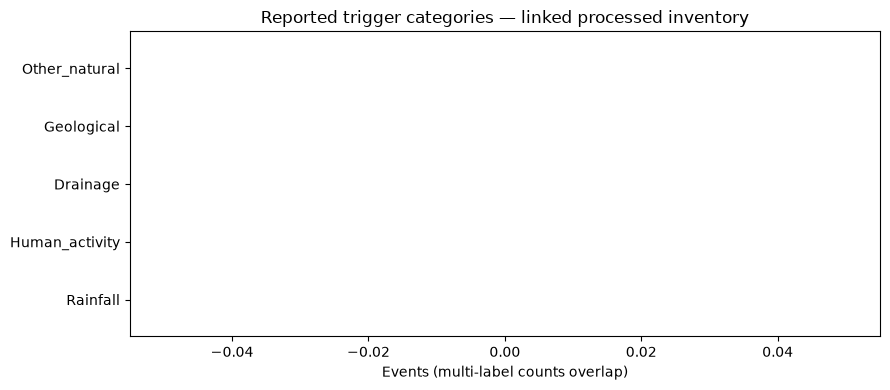

In [6]:
RULES={
 'Rainfall':r'\b(?:rain(?:fall)?|downpour|monsoon|prolonged[_\s-]+rain|continuous[_\s-]+rain|hujan(?:\s+l[eb]at)?|hujan\s+berterusan|ribut\s+hujan)\b',
 'Human_activity':r'\b(?:construction|excavat(?:ion|ing)|mining|quarry|hill\s*cutting|hillcutting|slope\s+cutting|earthwork|deforestation|logging|land\s+clearing|pembinaan|pengorekan|perlombongan|kuari|pemotongan\s+bukit|kerja\s+tanah|pembalakan|tambakan)\b',
 'Drainage':r'\b(?:drainage|drain|blocked\s+drain|culvert|flood(?:ing)?|riverbank|saliran|perparitan|longkang|tersumbat|banjir|air\s+larian|aliran\s+permukaan|air\s+tanah|tepu\s+air)\b',
 'Geological':r'\b(?:geolog(?:y|ical)|fault(?:ing)?|weathered\s+rock|weak\s+rock|soil\s+instability|ground\s+condition|geologi|gologi|batuan|sesar|tanah\s+(?:tidak\s+stabil|lemah)|bahan\s+geologi|material\s+longgar|bahan\s+sensitif|sensitif\s+material|baki\s+granit|berpasir)\b',
 'Other_natural':r'\b(?:earthquake|seismic|tropical\s+cyclone|typhoon|gempa|taufan)\b'
}
NEGATION=re.compile(r'\b(?:no|not|without|tiada|bukan|tidak|none)\b',re.I)
UNCERTAIN=re.compile(r'\b(?:possible|possibly|suspect(?:ed)?|might|may|berkemungkinan|mungkin|disyaki)\b',re.I)
UNKNOWN=re.compile(r'^(?:\s*|unknown|not\s+reported|not\s+available|n/?a|tiada\s+maklumat|tidak\s+diketahui|unspecified|other|lain[-_ ]lain|none|nan|null|-)\s*$',re.I)
def classify_report(s):
    t=str(s if pd.notna(s) else '').strip().lower().replace('_',' ')
    if UNKNOWN.fullmatch(t):return {'labels':[],'status':'UNKNOWN','needs_review':False}
    matches=[];review=bool(UNCERTAIN.search(t))
    for label,pattern in RULES.items():
        for m in re.finditer(pattern,t,re.I):
            left=t[max(0,m.start()-35):m.start()];left=re.split(r'[;,.|]',left)[-1]
            if NEGATION.search(left):review=True;continue
            matches.append(label)
    matches=sorted(set(matches))
    return {'labels':matches,'status':'REPORTED_CATEGORY_MATCH' if matches else 'OTHER_UNSPECIFIED','needs_review':review or not bool(matches)}
# Classify all raw rows before recomputing source availability. Explicit 'unknown'/'other' is NOT a reported cause.
raw_classified=raw.original_trigger_text.apply(classify_report)
raw['raw_trigger_status']=raw_classified.map(lambda d:d['status'])
raw['raw_trigger_labels']=raw_classified.map(lambda d:' | '.join(d['labels']))
raw['raw_has_reported_cause']=raw['raw_trigger_status'].ne('UNKNOWN') & raw.original_trigger_text.ne('')
raw['raw_has_recognised_category']=raw_classified.map(lambda d:bool(d['labels']))
raw.to_csv(OUT/'03_raw_trigger_matching_audit.csv',index=False)
raw_audit=raw.groupby('source',dropna=False).agg(raw_records=('row_index','size'),raw_with_reported_trigger=('raw_has_reported_cause','sum'),raw_recognised_categories=('raw_has_recognised_category','sum'),verified_linked_rows=('event_candidate_id','count')).reset_index()
raw_audit['raw_missing_or_unknown']=raw_audit.raw_records-raw_audit.raw_with_reported_trigger
raw_audit['raw_trigger_availability_pct']=np.where(raw_audit.raw_records.gt(0),100*raw_audit.raw_with_reported_trigger/raw_audit.raw_records,np.nan)
raw_audit.to_csv(OUT/'04_raw_source_trigger_availability.csv',index=False);display(raw_audit)
raw_freq=[]
for src,g in raw.groupby('source',dropna=False):
    for label in RULES:
        raw_freq.append({'source':src,'category':label,'raw_records':len(g),'events_reporting_category':int(g.raw_trigger_labels.str.split(' | ',regex=False).apply(lambda ss:label in ss).sum())})
raw_freq=pd.DataFrame(raw_freq);raw_freq.to_csv(OUT/'19_raw_multilabel_by_source.csv',index=False);display(raw_freq)
raw[raw.raw_trigger_status.ne('UNKNOWN') & raw.raw_trigger_labels.eq('')].to_csv(OUT/'20_raw_trigger_manual_review.csv',index=False)
classified=master.original_trigger_text.apply(classify_report)
master['trigger_labels']=classified.map(lambda x:' | '.join(x['labels']))
master['trigger_status']=classified.map(lambda x:x['status']);master['needs_manual_review']=classified.map(lambda x:x['needs_review'])
for k in RULES:master['trigger_'+k]=classified.map(lambda x:k in x['labels'])
master['reported_label_count']=classified.map(lambda x:len(x['labels']))
master['multi_trigger']=master.reported_label_count.ge(2)
master['has_reported_text']=master.trigger_status.ne('UNKNOWN') & master.original_trigger_text.ne('')
# Multi-label frequencies are not mutually exclusive; percentages may total > 100%.
freq=pd.DataFrame([{'category':k,'events':int(master['trigger_'+k].sum()),'share_of_all_processed_pct':100*master['trigger_'+k].mean()} for k in RULES]);display(freq)
print('Multi-label events:',master.multi_trigger.sum(),'| Needs human review:',master.needs_manual_review.sum())
master.to_csv(OUT/'06_processed_events_reported_multilabel_triggers.csv',index=False)
freq.to_csv(OUT/'07_multilabel_trigger_frequencies.csv',index=False)
review=master[master.needs_manual_review & master.has_reported_text][['event_candidate_id','source','original_trigger_text','trigger_labels','trigger_status']]
review.to_csv(OUT/'08_manual_trigger_coding_review.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4));ax.barh(freq.category,freq.events);ax.set(xlabel='Events (multi-label counts overlap)',title='Reported trigger categories — linked processed inventory');fig.tight_layout();fig.savefig(FIG/'01_reported_trigger_categories.png',dpi=180);plt.show()

### 3A. Verify the uploaded trigger field semantics before interpreting processed totals
The following source-level QA includes explicit `unknown` and blank values, both `Punca` fields, and source-native cause text. All raw records remain visible even if a processed crosswalk has not been established. Descriptions and news excerpts are **not** treated as cause-label fields.

In [7]:
if source_raw:
    examples=[]
    for src,d in source_raw.items():
        cols=trigger_columns(d,src)
        if not cols:
            examples.append({'source':src,'trigger_columns':'NONE','raw_rows':len(d),'example':'NO REPORTED TRIGGER FIELD'})
            continue
        descriptions=make_text(d,cols)
        for val,n_count in descriptions.value_counts(dropna=False).head(25).items():
            examples.append({'source':src,'trigger_columns':' | '.join(cols),'raw_rows':len(d),'example':val,'raw_value_frequency':n_count})
    source_examples=pd.DataFrame(examples)
    display(source_examples)
    source_examples.to_csv(OUT/'21_raw_original_trigger_values.csv',index=False)
    for src,d in source_raw.items():
        print(src,'raw records:',len(d),'trigger columns:',trigger_columns(d,src))
else: print('No raw source files loaded; set SOURCE_OVERRIDE in Section 0.')

,source,trigger_columns,raw_rows,example,raw_value_frequency
0,COOLR,landslide_trigger,236,downpour,110.0
1,COOLR,landslide_trigger,236,rain,59.0
2,COOLR,landslide_trigger,236,continuous_rain,32.0
3,COOLR,landslide_trigger,236,,21.0
4,COOLR,landslide_trigger,236,construction,5.0
5,COOLR,landslide_trigger,236,other,3.0
6,COOLR,landslide_trigger,236,tropical_cyclone,2.0
7,COOLR,landslide_trigger,236,flooding,2.0
8,COOLR,landslide_trigger,236,mining,1.0
9,COOLR,landslide_trigger,236,monsoon,1.0


COOLR raw records: 236 trigger columns: ['landslide_trigger']
GFLD raw records: 61 trigger columns: ['Trigger_']
JMG_original raw records: 52 trigger columns: ['Punca_Tana', 'Punca__']
JMG_archive raw records: 366 trigger columns: []


## 4. Inventory, date, geographic and environmental coverage
The environmental-feature file is event-level. The modelling CSVs contain positive and background records, but only `target==1` is eligible for this **historical triggering** exploration. Sidecar enhancement rows are joined on `sample_id` only, with one-to-one validation. **Do not use background controls as historical trigger observations.**

Dates with year-only/month-only precision must not receive event-specific antecedent rainfall interpretations.

In [8]:
feature=pd.read_csv(FEATURES,low_memory=False) if FEATURES.exists() else pd.DataFrame()
if len(feature):
    assert 'event_candidate_id' in feature and feature.event_candidate_id.is_unique,'Environmental features must have unique curated IDs'
    fcols=[x for x in feature.columns if x not in master.columns or x=='event_candidate_id']
    master=master.merge(feature[fcols],on='event_candidate_id',how='left',validate='one_to_one',indicator='_feature_match')
    master['environmental_feature_matched']=master._feature_match.eq('both');master=master.drop(columns='_feature_match')
else:master['environmental_feature_matched']=False
positive_sets=[]
for branch,p in [('static',STATIC),('temporal',TEMPORAL)]:
    if p.exists():
        t=pd.read_csv(p,low_memory=False);assert {'target','event_candidate_id','sample_id'}.issubset(t),'Model data missing matching keys'
        c=t[t.target.eq(1)].copy();assert c.sample_id.is_unique
        c['model_branch']=branch;positive_sets.append(c)
        master['in_'+branch+'_model']=master.event_candidate_id.isin(c.event_candidate_id.astype(str))
    else:master['in_'+branch+'_model']=False
if positive_sets:
    model_cases=pd.concat(positive_sets,ignore_index=True)
    if ENHANCEMENT.exists():
        e=pd.read_csv(ENHANCEMENT,low_memory=False); assert 'sample_id' in e and e.sample_id.is_unique
        add=['sample_id']+[c for c in e if c not in model_cases.columns and c not in ('matched_event_id','_key')]
        model_cases=model_cases.merge(e[add],on='sample_id',how='left',validate='many_to_one')
    model_cases.to_csv(OUT/'09_positive_model_case_feature_audit.csv',index=False)
else:model_cases=pd.DataFrame()
if 'event_date' in master:
    master['event_date_parsed']=pd.to_datetime(master.event_date,errors='coerce')  # Processed inventory ISO/date convention only; source epoch-milliseconds are audited separately
    master['event_year']=master.event_date_parsed.dt.year
else:master['event_date_parsed']=pd.NaT;master['event_year']=np.nan
if 'date_precision' in master:
    master['is_day_precise']=master.date_precision.astype(str).str.lower().isin(['day','daily','exact','day_precision'])
else:master['is_day_precise']=False
# Source and year coverage are descriptive. Missing year is retained.
cover=master.groupby('source',dropna=False).agg(total_candidates=('event_candidate_id','size'),reported_text=('has_reported_text','sum'),coded_category=('reported_label_count',lambda s:s.gt(0).sum()),multi_trigger=('multi_trigger','sum'),environmental_matched=('environmental_feature_matched','sum'),day_precise=('is_day_precise','sum')).reset_index()
cover['reported_text_pct']=100*cover.reported_text/cover.total_candidates
display(cover);cover.to_csv(OUT/'10_processed_source_coverage.csv',index=False)
by_year=master.groupby(['source','event_year'],dropna=False).agg(events=('event_candidate_id','size'),reported=('has_reported_text','sum')).reset_index();by_year.to_csv(OUT/'11_source_year_missingness.csv',index=False)
area_col=next((x for x in ['state','state_name','negeri','district','daerah'] if x in master),None)
if area_col:
    by_area=master.groupby(['source',area_col],dropna=False).agg(events=('event_candidate_id','size'),reported=('has_reported_text','sum')).reset_index();by_area.to_csv(OUT/'12_source_area_missingness.csv',index=False)
else:print('No validated administrative area column in processed table; geographic stratification skipped.')
print('CAUTION: event_date_parsed is not proof of day-level precision; check the original date_precision codes before using rainfall.')
print('Observed date_precision values:',master.date_precision.value_counts(dropna=False).head(20).to_dict() if 'date_precision' in master else 'COLUMN ABSENT')

C:\Users\User\AppData\Local\Temp\ipykernel_27340\2082023701.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  master=master.merge(feature[fcols],on='event_candidate_id',how='left',validate='one_to_one',indicator='_feature_match')
C:\Users\User\AppData\Local\Temp\ipykernel_27340\2082023701.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  master=master.merge(feature[fcols],on='event_candidate_id',how='left',validate='one_to_one',indicator='_feature_match')
C:\Users\User\AppData\Local\Temp\ipykernel_27340\2082023701.py:6: Perf

,source,total_candidates,reported_text,coded_category,multi_trigger,environmental_matched,day_precise,reported_text_pct
0,COOLR,236,0,0,0,236,0,0.0
1,GFLD,61,0,0,0,61,0,0.0
2,JMG_archive,364,0,0,0,364,361,0.0
3,JMG_original,52,0,0,0,52,47,0.0


No validated administrative area column in processed table; geographic stratification skipped.
CAUTION: event_date_parsed is not proof of day-level precision; check the original date_precision codes before using rainfall.
Observed date_precision values: {'day': 408, 'day_timestamp_field': 297, 'year_only': 4, 'month_year': 2, 'invalid_components': 2}


## 5. Descriptive environmental comparisons by *reported* trigger
**No hypothesis tests or causal claims.** For rainfall, runoff and soil moisture, include only records with verified day-precision dates and valid pre-event feature provenance. Where the data were extracted using a same-day or post-event window, **exclude that feature until its time-window bounds are checked against Notebook 02**. The default list here is conservative and requires an explicit provenance confirmation for temporal variables.

In [9]:
STATIC_CANDIDATES=['elevation_m','slope_deg','aspect_deg','road_distance_m','waterway_distance_m','merit_hand_m','merit_upstream_area_km2',
                   'soil_clay_surface','soil_sand_surface','soil_silt_surface','soil_bdod_surface','ndvi_pre_event','ndvi_change_2y','forest_loss_5y_250m_pct',
                   'profile_curvature','plan_curvature','twi','spi','regional_fault_distance_m','major_fault_window_distance_m']
TEMPORAL_CANDIDATES=['rain_1d_mm','rain_3d_mm','rain_7d_mm','rain_14d_mm','rain_30d_mm','soil_moisture_7d_m3m3','runoff_7d_mm','runoff_30d_mm']
# Explicit opt-in ONLY after confirming temporal window bounds/reference-date consistency in Notebook 02.
PRE_EVENT_TEMPORAL_VERIFIED=False
if model_cases.empty:
    print('Model case CSV not available. Using direct event-level feature file; model sidecar-dependent measures unavailable.')
    analysis=master.copy()
else:
    # Give preference to temporal case rows when available; static cases cover events without temporal data.
    order={'temporal':0,'static':1}
    model_cases['_priority']=model_cases.model_branch.map(order)
    m=model_cases.sort_values('_priority').drop_duplicates('event_candidate_id')
    cols=['event_candidate_id']+[c for c in STATIC_CANDIDATES+TEMPORAL_CANDIDATES if c in m]
    m=m[cols]
    analysis=master.drop(columns=[c for c in STATIC_CANDIDATES+TEMPORAL_CANDIDATES if c in master and c in m]).merge(m,on='event_candidate_id',how='left',validate='one_to_one')
    # Fallback event-level measured predictors only for events absent from model cohorts.
    if len(feature):
        for col in STATIC_CANDIDATES+TEMPORAL_CANDIDATES:
            if col in feature:
                look=feature.set_index('event_candidate_id')[col]
                if col not in analysis:analysis[col]=analysis.event_candidate_id.map(look)
                else:analysis[col]=analysis[col].combine_first(analysis.event_candidate_id.map(look))
available_static=[x for x in STATIC_CANDIDATES if x in analysis]
available_temporal=[x for x in TEMPORAL_CANDIDATES if x in analysis]
print('Static feature columns:',available_static)
print('Temporal feature columns:',available_temporal)
print('Temporal comparisons ENABLED:',PRE_EVENT_TEMPORAL_VERIFIED)
if not PRE_EVENT_TEMPORAL_VERIFIED:print('Temporal feature summaries held back pending source-window/date verification (set flag True deliberately after confirmation).')
rows=[]
for cat in RULES:
    subset=analysis[analysis['trigger_'+cat]]
    for feat in available_static + (available_temporal if PRE_EVENT_TEMPORAL_VERIFIED else []):
        s=pd.to_numeric(subset[feat],errors='coerce')
        if feat in TEMPORAL_CANDIDATES:s=s[subset.is_day_precise]
        rows.append({'category':cat,'feature':feat,'reported_events':len(subset),'n_valid':int(s.notna().sum()),'median':s.median(),'q25':s.quantile(.25),'q75':s.quantile(.75),'mean':s.mean(),'source_count':subset.loc[s.dropna().index,'source'].nunique()})
summary=pd.DataFrame(rows,columns=['category','feature','reported_events','n_valid','median','q25','q75','mean','source_count'])
if len(summary): display(summary.sort_values(['category','feature']).head(40))
else: print('No relevant environmental features in available sources; output is empty until processed feature files are present.')
summary.to_csv(OUT/'13_environmental_summaries_by_trigger.csv',index=False)
for feat in [x for x in ['slope_deg','elevation_m','road_distance_m','merit_hand_m','rain_7d_mm'] if x in analysis and (x not in TEMPORAL_CANDIDATES or PRE_EVENT_TEMPORAL_VERIFIED)]:
    groups=[pd.to_numeric(analysis.loc[analysis['trigger_'+cat],feat],errors='coerce').dropna().to_numpy() for cat in RULES]
    keep=[(cat,x) for cat,x in zip(RULES,groups) if len(x)>=3]
    if len(keep)<2:continue
    fig,ax=plt.subplots(figsize=(9,4.5));ax.boxplot([x for _,x in keep],tick_labels=[c for c,_ in keep],showfliers=False)
    ax.set(ylabel=feat,title=f'{feat}: reported categories (overlapping groups; non-causal)');ax.tick_params(axis='x',rotation=25);fig.tight_layout();fig.savefig(FIG/f'02_feature_{feat}.png',dpi=180);plt.show()
analysis.to_csv(OUT/'14_event_trigger_environmental_analysis.csv',index=False)

Static feature columns: ['elevation_m', 'slope_deg', 'aspect_deg', 'road_distance_m', 'waterway_distance_m', 'merit_hand_m', 'merit_upstream_area_km2', 'soil_clay_surface', 'soil_sand_surface', 'soil_silt_surface', 'soil_bdod_surface', 'ndvi_pre_event', 'ndvi_change_2y', 'forest_loss_5y_250m_pct', 'regional_fault_distance_m', 'major_fault_window_distance_m']
Temporal feature columns: ['rain_1d_mm', 'rain_3d_mm', 'rain_7d_mm', 'rain_14d_mm', 'rain_30d_mm', 'soil_moisture_7d_m3m3', 'runoff_7d_mm', 'runoff_30d_mm']
Temporal comparisons ENABLED: False
Temporal feature summaries held back pending source-window/date verification (set flag True deliberately after confirmation).


,category,feature,reported_events,n_valid,median,q25,q75,mean,source_count
34,Drainage,aspect_deg,0,0,NaN,NaN,NaN,NaN,0
32,Drainage,elevation_m,0,0,NaN,NaN,NaN,NaN,0
45,Drainage,forest_loss_5y_250m_pct,0,0,NaN,NaN,NaN,NaN,0
47,Drainage,major_fault_window_distance_m,0,0,NaN,NaN,NaN,NaN,0
37,Drainage,merit_hand_m,0,0,NaN,NaN,NaN,NaN,0
38,Drainage,merit_upstream_area_km2,0,0,NaN,NaN,NaN,NaN,0
44,Drainage,ndvi_change_2y,0,0,NaN,NaN,NaN,NaN,0
43,Drainage,ndvi_pre_event,0,0,NaN,NaN,NaN,NaN,0
46,Drainage,regional_fault_distance_m,0,0,NaN,NaN,NaN,NaN,0
35,Drainage,road_distance_m,0,0,NaN,NaN,NaN,NaN,0


## 6. Unknown-trigger environmental compatibility — conservative, transparent report
Only trigger-**compatible conditions**, never inferred causes. References are **reported-category environmental distributions**, which can be confounded by source, geography and reporting practice. A static slope/road distance cannot establish that rainfall or construction triggered a landslide.

Default rule: require event-level day precision, explicitly verified pre-event measurements, a minimum reference cohort, and an observed extreme versus a cross-source reference distribution. Otherwise return **Insufficient evidence**. This notebook intentionally does not manufacture confidence percentages.

In [10]:
# Descriptive screening thresholds are user-adjustable exploratory heuristics, not validated trigger classifiers.
MIN_REFERENCE_EVENTS=15; MIN_REFERENCE_SOURCES=2
unknown=analysis[~analysis.has_reported_text].copy()
if 'event_year' not in unknown:unknown['event_year']=np.nan
compat=[]
for _,r in unknown.iterrows():
    hits=[];evidence=[];caveats=[]
    if not bool(r.get('is_day_precise',False)):caveats.append('Unverified day-precision event date')
    if not PRE_EVENT_TEMPORAL_VERIFIED:caveats.append('Antecedent meteorological timing not verified')
    if PRE_EVENT_TEMPORAL_VERIFIED and bool(r.get('is_day_precise',False)):
        reference=analysis[analysis.trigger_Rainfall & analysis.is_day_precise]
        reference=reference[reference.source.ne(r.source)] # check external-source transferability
        if len(reference)>=MIN_REFERENCE_EVENTS and reference.source.nunique()>=MIN_REFERENCE_SOURCES:
            for f in ['rain_3d_mm','rain_7d_mm','rain_14d_mm','rain_30d_mm']:
                if f in reference and pd.notna(r.get(f)):
                    vals=pd.to_numeric(reference[f],errors='coerce').dropna()
                    if len(vals)>=MIN_REFERENCE_EVENTS and float(r[f])>=vals.quantile(.75):
                        hits.append('Rainfall-compatible');evidence.append(f'{f}={float(r[f]):.2f}, >= reference Q75={vals.quantile(.75):.2f}')
        else:caveats.append('Insufficient independent reported-rainfall reference cohort')
    # No static proxy is permitted to assert human construction or infrastructure drainage causation.
    compat.append({'event_candidate_id':r.event_candidate_id,'source':r.source,'event_date':r.get('event_date',np.nan),
         'original_reported_trigger':r.original_trigger_text,'observed_condition_screen': ' | '.join(sorted(set(hits))) if hits else 'Insufficient evidence',
         'supporting_environmental_evidence':' | '.join(evidence),'uncertainty_notes':' | '.join(caveats) if caveats else 'Exploratory; source bias and confounding remain',
         'independent_verification_status':'NOT_VERIFIED','inferred_cause':'NOT_ASSIGNED'})
compat=pd.DataFrame(compat);display(compat.head(15));compat.to_csv(OUT/'15_unknown_trigger_compatibility_report.csv',index=False)
print('Unknown reported-trigger records:',len(compat),'| sufficient evidence flags:',int(compat.observed_condition_screen.ne('Insufficient evidence').sum()) if len(compat) else 0)

,event_candidate_id,source,event_date,original_reported_trigger,observed_condition_screen,supporting_environmental_evidence,uncertainty_notes,independent_verification_status,inferred_cause
0,JMG_original:00001,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
1,JMG_original:00002,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
2,JMG_original:00003,JMG_original,2021-12-19,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
3,JMG_original:00004,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
4,JMG_original:00005,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
5,JMG_original:00006,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
6,JMG_original:00007,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
7,JMG_original:00008,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
8,JMG_original:00009,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED
9,JMG_original:00010,JMG_original,2021-12-18,,Insufficient evidence,,Antecedent meteorological timing not verified,NOT_VERIFIED,NOT_ASSIGNED


Unknown reported-trigger records: 713 | sufficient evidence flags: 0


## 6A. Historical rainfall comparison and engineered predictors — separate questions

**Question A (reported-trigger compatibility):** For matched landslide events with an independently reported rainfall trigger, describe prior rainfall distributions. Compare unknown-trigger events to that reference group with *percentiles* and record uncertainties. A high percentile means **rainfall-compatible conditions**, not an assigned cause. A percentile derived only from already-reported rainfall events is not a calibrated probability of rainfall having caused the landslide. Cross-source reporting bias and missing-trigger bias can invalidate automatic classification.

**Question B (main susceptibility prediction):** Derived rainfall predictors such as prior `7d / 30d` rainfall concentration or a slope–rainfall interaction can be computed from environmental inputs for **both cases and existing matched controls**. These predictors do not need reported trigger labels. Do not include `trigger_Rainfall`, unknown-trigger compatibility, or a category score trained on landslide reports in the main classifier.

This section intentionally performs **no model training**. Rainfall calculations are blocked until the Notebook 02 date/feature window audit is confirmed by setting `PRE_EVENT_TEMPORAL_VERIFIED=True` in Section 5. The output explicitly records whether the experiment is blocked or eligible. For an actual future model experiment, preserve all original CV groupings and avoid using holdout labels. The choice of new candidate features must be declared before comparative modelling.

In [11]:
# ANALYSIS ONLY: no changes to inventory/model outputs. This cell produces transparent candidate features.
compatibility_rows=[]
feature_audit=[]
if not PRE_EVENT_TEMPORAL_VERIFIED:
    feature_audit.append({'check':'temporal_reference_date_and_window','status':'BLOCKED','detail':'Verify event/control reference dates and pre-event time windows in Notebook 02 before setting PRE_EVENT_TEMPORAL_VERIFIED=True'})
else:
    required={'rain_7d_mm','rain_30d_mm'}
    if not required.issubset(analysis.columns):
        feature_audit.append({'check':'rainfall_feature_availability','status':'BLOCKED','detail':f'Missing columns: {sorted(required-set(analysis.columns))}'})
    else:
        # Known-trigger distributions are descriptive and require verified linkage.
        known=analysis.loc[analysis['trigger_Rainfall'] & analysis['has_reported_text'] & analysis['is_day_precise']].copy()
        valid_known=known.loc[pd.to_numeric(known['rain_7d_mm'],errors='coerce').notna()].copy()
        sufficient=len(valid_known)>=15 and valid_known.source.nunique()>=2
        feature_audit.append({'check':'verified_reported_rainfall_reference','status':'READY_DESCRIPTIVE' if sufficient else 'INSUFFICIENT','detail':f'{len(valid_known)} valid known-rainfall events from {valid_known.source.nunique()} inventory sources; require >=15 and >=2 sources for the example percentile screen'})
        if sufficient:
            vals=pd.to_numeric(valid_known['rain_7d_mm'],errors='coerce').dropna().to_numpy()
            for _,r in analysis.loc[~analysis['has_reported_text']].iterrows():
                v=pd.to_numeric(pd.Series([r.get('rain_7d_mm')]),errors='coerce').iloc[0]
                valid=bool(r.get('is_day_precise',False)) and pd.notna(v)
                compatibility_rows.append({'event_candidate_id':r['event_candidate_id'],'source':r['source'],
                     'rain_7d_mm':v if valid else np.nan,
                     'percentile_within_reported_rainfall_events':float(100*(vals<=v).mean()) if valid else np.nan,
                     'reference_event_n':len(vals),'reference_source_n':valid_known.source.nunique(),
                     'assessment':'ENVIRONMENTAL COMPARISON ONLY' if valid else 'INSUFFICIENT_EVIDENCE',
                     'original_trigger':'UNKNOWN_OR_NOT_REPORTED','confirmed_cause':'NOT_ASSIGNED',
                     'caution':'Reference may be source-biased; percentile is not probability of rainfall causation'})
    if TEMPORAL.exists():
        mdl=pd.read_csv(TEMPORAL,low_memory=False)
        if {'sample_id','target','rain_7d_mm','rain_30d_mm','slope_deg'}.issubset(mdl):
            # For exploratory feature availability only: NO training, tuning, or holdout comparisons.
            z=mdl[['sample_id','target','rain_7d_mm','rain_30d_mm','slope_deg']].copy()
            for col in ['rain_7d_mm','rain_30d_mm','slope_deg']:z[col]=pd.to_numeric(z[col],errors='coerce')
            # Guard against division by zero. Zero 30-day rainfall -> undefined ratio, not infinity.
            z['rainfall_concentration_7d_30d']=z['rain_7d_mm']/z['rain_30d_mm'].where(z['rain_30d_mm']>0)
            z['rainfall_7d_x_slope']=z['rain_7d_mm']*z['slope_deg']
            feature_audit.append({'check':'all_case_and_control_feature_coverage','status':'DESCRIPTIVE_ONLY','detail':f'Rows {len(z)}, positive {int(z.target.eq(1).sum())}, controls {int(z.target.eq(0).sum())}, ratio defined {int(z.rainfall_concentration_7d_30d.notna().sum())}, interaction defined {int(z.rainfall_7d_x_slope.notna().sum())}'})
            z.to_csv(OUT/'23_exploratory_rainfall_feature_values_CASES_AND_CONTROLS.csv',index=False)
        else:
            feature_audit.append({'check':'all_case_and_control_feature_coverage','status':'BLOCKED','detail':'Missing required sample_id/target/rainfall/slope columns in temporal dataset'})
if not compatibility_rows:
    pd.DataFrame(columns=['event_candidate_id','source','rain_7d_mm','percentile_within_reported_rainfall_events','reference_event_n','reference_source_n','assessment','original_trigger','confirmed_cause','caution']).to_csv(OUT/'22_unknown_rainfall_reference_percentiles.csv',index=False)
else:pd.DataFrame(compatibility_rows).to_csv(OUT/'22_unknown_rainfall_reference_percentiles.csv',index=False)
qa=pd.DataFrame(feature_audit,columns=['check','status','detail']);qa.to_csv(OUT/'24_rainfall_feature_evidence_gate.csv',index=False);display(qa)
print('Rainfall reference evidence is descriptive; no missing cause is filled, and no classifier was retrained.')

,check,status,detail
0,temporal_reference_date_and_window,BLOCKED,Verify event/control reference dates and pre-e...


Rainfall reference evidence is descriptive; no missing cause is filled, and no classifier was retrained.


## 6B. Read-only date and meteorological provenance audit
The temporal dataset should contain one case and two controls per matched group, sharing **the same reference date**. A complete 1:2 triplet is necessary but does **not** prove the source event date is day-precise or the satellite extraction used correct timestamps. This section generates an evidence checklist and diagnostics; it does not enable temporal trigger inference automatically.

In [12]:
date_audit=[]; rainfall_quality=[]
if TEMPORAL.exists():
    tt=pd.read_csv(TEMPORAL,low_memory=False)
    mandatory=['sample_id','matched_event_id','target','reference_date','event_candidate_id']
    missing=[c for c in mandatory if c not in tt.columns]
    if missing:
        date_audit.append({'check':'temporal_required_columns','status':'FAIL','detail':', '.join(missing)})
    else:
        tt['target']=pd.to_numeric(tt['target'],errors='coerce')
        g=tt.groupby('matched_event_id',dropna=False)
        valid_triplet=g.target.agg(lambda s:len(s)==3 and s.eq(1).sum()==1 and s.eq(0).sum()==2)
        consistent_date=g.reference_date.nunique(dropna=False).eq(1)
        # Only cases carry event_candidate_id; controls identify the parent through matched_event_id.
        case_rows=tt.loc[tt.target.eq(1),['matched_event_id','event_candidate_id']].copy()
        case_rows['matched_event_id']=case_rows['matched_event_id'].astype('string')
        case_rows['event_candidate_id']=case_rows['event_candidate_id'].astype('string')
        case_rows['_valid_parent']=(case_rows['event_candidate_id'].notna() &
                                    case_rows['event_candidate_id'].eq(case_rows['matched_event_id']))
        consistent_parent=case_rows.groupby('matched_event_id')['_valid_parent'].agg(['all','size'])
        consistent_parent=consistent_parent['all'] & consistent_parent['size'].eq(1)
        # If some pandas versions handle apply differently, this check still compares case IDs only.
        consistent_parent=consistent_parent.reindex(valid_triplet.index,fill_value=False)
        for name,passed,detail in [
            ('complete_matched_triplets',bool(valid_triplet.all()),f'{int(valid_triplet.sum())}/{len(valid_triplet)} complete groups'),
            ('identical_case_control_reference_date',bool(consistent_date.all()),f'{int(consistent_date.sum())}/{len(consistent_date)} groups'),
            ('case_event_id_matches_matched_parent_id',bool(consistent_parent.all()),f'{int(consistent_parent.sum())}/{len(consistent_parent)} groups; controls are allowed blank event_candidate_id'),
            ('unique_sample_ids',bool(tt.sample_id.is_unique),f'{tt.sample_id.nunique()}/{len(tt)} unique sample IDs'),
            ('parseable_reference_dates',bool(pd.to_datetime(tt.reference_date,errors='coerce').notna().all()),'Date parsing only, NOT evidence of true failure timing')]:
            date_audit.append({'check':name,'status':'PASS' if passed else 'FAIL','detail':detail})
        rr=[f'rain_{k}d_mm' for k in (1,3,7,14,30) if f'rain_{k}d_mm' in tt]
        for f in rr:
            values=pd.to_numeric(tt[f],errors='coerce').replace([np.inf,-np.inf],np.nan)
            rainfall_quality.append({'feature':f,'rows':len(tt),'missing':int(values.isna().sum()),
                                     'negative':int(values.lt(0).sum()),'zero':int(values.eq(0).sum()),
                                     'p50_mm':values.median(),'p99_mm':values.quantile(.99),'max_mm':values.max()})
        if len(rr)==5:
            a=tt[rr].apply(pd.to_numeric,errors='coerce')
            ordered=(a.diff(axis=1).iloc[:,1:]>=-1e-7).all(axis=1) | a.isna().any(axis=1)
            date_audit.append({'check':'nested_rainfall_window_monotonicity',
                               'status':'PASS' if ordered.all() else 'FAIL',
                               'detail':f'{int((~ordered).sum())} rows with shorter-window total exceeding longer window'})
else:
    date_audit.append({'check':'temporal_model_dataset_available','status':'BLOCKED','detail':'Temporal model dataset missing'})
date_audit.extend([
    {'check':'source_event_date_day_precision','status':'MANUAL_VERIFY','detail':'Check Notebook 01 event-date lineage; valid-looking ISO dates are insufficient'},
    {'check':'IMERG_half_hour_accumulation_units','status':'MANUAL_VERIFY','detail':'Confirm source band mm/hour; half-hour integration and valid image count per window'},
    {'check':'event_day_excluded_and_time_zone','status':'MANUAL_VERIFY','detail':'Confirm exclusive end at UTC reference-day boundary, plus event local-day conversion'},
    {'check':'satellite_availability_and_missing_frames','status':'MANUAL_VERIFY','detail':'Check IMERG coverage and missing-frame policy per event/control window'},
    {'check':'post_event_use','status':'MANUAL_VERIFY','detail':'Verify no later timestamps used; retrospective final product != real-time availability'}])
pd.DataFrame(date_audit).to_csv(OUT/'27_temporal_reference_date_and_provenance_audit.csv',index=False)
pd.DataFrame(rainfall_quality).to_csv(OUT/'28_rainfall_value_quality_summary.csv',index=False)
display(pd.DataFrame(date_audit));display(pd.DataFrame(rainfall_quality))
print('No temporal evidence gate has been automatically unlocked.')

,check,status,detail
0,complete_matched_triplets,PASS,643/643 complete groups
1,identical_case_control_reference_date,PASS,643/643 groups
2,case_event_id_matches_matched_parent_id,PASS,643/643 groups; controls are allowed blank eve...
3,unique_sample_ids,PASS,1929/1929 unique sample IDs
4,parseable_reference_dates,PASS,"Date parsing only, NOT evidence of true failur..."
5,nested_rainfall_window_monotonicity,PASS,0 rows with shorter-window total exceeding lon...
6,source_event_date_day_precision,MANUAL_VERIFY,Check Notebook 01 event-date lineage; valid-lo...
7,IMERG_half_hour_accumulation_units,MANUAL_VERIFY,Confirm source band mm/hour; half-hour integra...
8,event_day_excluded_and_time_zone,MANUAL_VERIFY,Confirm exclusive end at UTC reference-day bou...
9,satellite_availability_and_missing_frames,MANUAL_VERIFY,Check IMERG coverage and missing-frame policy ...


,feature,rows,missing,negative,zero,p50_mm,p99_mm,max_mm
0,rain_1d_mm,1929,0,0,64,15.445000,219.594997,248.359991
1,rain_3d_mm,1929,0,0,18,51.889998,350.728991,520.929989
2,rain_7d_mm,1929,0,0,6,104.774998,398.128790,737.859982
3,rain_14d_mm,1929,0,0,1,149.479997,536.630587,1142.354974
4,rain_30d_mm,1929,0,0,0,314.144993,745.302784,1522.204964


No temporal evidence gate has been automatically unlocked.


## 7. Evidence quality, source bias and feature feasibility
Feature proposals must be measurable independently for **both landslide and matched background observations**, available at prediction time, and evaluated only under the **existing frozen geographic folds** if a later exploratory training experiment is justified.

**New exploratory evidence files:** `22_unknown_rainfall_reference_percentiles.csv` (only after verified timing and sufficient linked known-rainfall references), `23_exploratory_rainfall_feature_values_CASES_AND_CONTROLS.csv` (only after verified timing), and `24_rainfall_feature_evidence_gate.csv` (always). Percentiles are not causal probabilities.

In [13]:
quality=[]
for source,g in analysis.groupby('source',dropna=False):
    quality.append({'source':source,'processed_events':len(g),'reported_trigger_events':int(g.has_reported_text.sum()),
      'multi_label_events':int(g.multi_trigger.sum()),'manual_review_events':int(g.needs_manual_review.sum()),
      'day_precise_events':int(g.is_day_precise.sum()),'reporting_coverage_pct':100*g.has_reported_text.mean()})
quality=pd.DataFrame(quality);quality.to_csv(OUT/'16_source_reporting_quality.csv',index=False);display(quality)
features_to_consider=[
 ('max_rain_7d','Maximum daily antecedent rainfall in prior 7 days','Requires daily rain source, known event/control reference dates, pre-event windows','PENDING_DATA'),
 ('consecutive_wet_days','Consecutive wet days before reference date','Daily rainfall availability and predefined wet-day threshold','PENDING_DATA'),
 ('rainfall_anomaly','Antecedent rainfall anomaly versus historical local climatology','Historical baseline, reference-date matching, leakage-safe seasonal normal','PENDING_DATA'),
 ('rainfall_concentration','7-day/30-day antecedent rainfall concentration','Existing 7d and 30d rainfall; verify both windows end before event/reference date','TIMING_VERIFY'),
 ('rain_slope_interaction','Antecedent rainfall × slope interaction','Slope plus antecedent rainfall for positive and matched controls','TIMING_VERIFY'),
 ('rain_twi_interaction','Antecedent rainfall × TWI interaction','DEM-based TWI not confirmed and rainfall timing requires audit','MISSING_TWI'),
 ('profile_plan_curvature','Profile / plan curvature','Consistent DEM source/resolution, pre-event static extraction','NEW_EXTRACTION'),
 ('twi','Topographic Wetness Index','DEM flow-accumulation preprocessing; controls and cases; redundancy check against HAND/upstream area','NEW_EXTRACTION'),
 ('human_disturbance','Independently measured human disturbance','Historical construction/land use layers with temporal provenance; road distance alone insufficient','PENDING_DATA'),
 ('engineered_drainage','Engineered drainage condition','Historical drain network / capacity; natural TWI not a substitute','PENDING_DATA')]
feas=pd.DataFrame(features_to_consider,columns=['predictor','rationale','requirements','preliminary_status']);feas.to_csv(OUT/'17_candidate_predictor_feasibility.csv',index=False);display(feas)
assessment={'processed_event_candidates':int(len(master)),'trigger_reported_n':int(master.has_reported_text.sum()),
 'multi_trigger_n':int(master.multi_trigger.sum()),'unknown_trigger_n':int((~master.has_reported_text).sum()),
 'unmatched_raw_source_rows':int(raw.event_candidate_id.isna().sum()),'temporal_provenance_confirmed':bool(PRE_EVENT_TEMPORAL_VERIFIED),
 'suitable_for_automatic_trigger_classifier':'NOT_ESTABLISHED',
 'recommended_model_action':'NO RETRAINING FROM THIS NOTEBOOK; investigate trigger completeness and time provenance first',
 'validation_warning':'Previously inspected 5-km spatial folds support exploratory comparisons only; frozen historical holdout untouched'}
(OUT/'18_conclusion_and_safeguards.json').write_text(json.dumps(assessment,indent=2),encoding='utf-8')
print(json.dumps(assessment,indent=2));print('Outputs saved to',OUT)

,source,processed_events,reported_trigger_events,multi_label_events,manual_review_events,day_precise_events,reporting_coverage_pct
0,COOLR,236,0,0,0,0,0.0
1,GFLD,61,0,0,0,0,0.0
2,JMG_archive,364,0,0,0,361,0.0
3,JMG_original,52,0,0,0,47,0.0


,predictor,rationale,requirements,preliminary_status
0,max_rain_7d,Maximum daily antecedent rainfall in prior 7 days,"Requires daily rain source, known event/contro...",PENDING_DATA
1,consecutive_wet_days,Consecutive wet days before reference date,Daily rainfall availability and predefined wet...,PENDING_DATA
2,rainfall_anomaly,Antecedent rainfall anomaly versus historical ...,"Historical baseline, reference-date matching, ...",PENDING_DATA
3,rainfall_concentration,7-day/30-day antecedent rainfall concentration,Existing 7d and 30d rainfall; verify both wind...,TIMING_VERIFY
4,rain_slope_interaction,Antecedent rainfall × slope interaction,Slope plus antecedent rainfall for positive an...,TIMING_VERIFY
5,rain_twi_interaction,Antecedent rainfall × TWI interaction,DEM-based TWI not confirmed and rainfall timin...,MISSING_TWI
6,profile_plan_curvature,Profile / plan curvature,"Consistent DEM source/resolution, pre-event st...",NEW_EXTRACTION
7,twi,Topographic Wetness Index,DEM flow-accumulation preprocessing; controls ...,NEW_EXTRACTION
8,human_disturbance,Independently measured human disturbance,Historical construction/land use layers with t...,PENDING_DATA
9,engineered_drainage,Engineered drainage condition,Historical drain network / capacity; natural T...,PENDING_DATA


{
  "processed_event_candidates": 713,
  "trigger_reported_n": 0,
  "multi_trigger_n": 0,
  "unknown_trigger_n": 713,
  "unmatched_raw_source_rows": 715,
  "temporal_provenance_confirmed": false,
  "suitable_for_automatic_trigger_classifier": "NOT_ESTABLISHED",
  "recommended_model_action": "NO RETRAINING FROM THIS NOTEBOOK; investigate trigger completeness and time provenance first",
  "validation_warning": "Previously inspected 5-km spatial folds support exploratory comparisons only; frozen historical holdout untouched"
}
Outputs saved to C:\landslide_fyp\outputs\historical_trigger_analysis


## 8. What to report in FYP Chapter 4
1. **Data Understanding:** Source counts, reported-trigger coverage, missingness by source/year/state, and differences between raw totals and processed unique candidate IDs (outputs 01–12).
2. **Data Preparation:** Auditable multi-label dictionary, exact-event linking, source-column identification, unmatched row caveats (outputs 02–08).
3. **Exploratory Analysis:** Descriptive predictor distributions and the number of events/independent inventory sources for each category (outputs 13–14, figures).
4. **Uncertainty:** Unknown-trigger screening results (output 15), manual coding-review count, temporal provenance and missing-date limitations (outputs 16 and 18).
5. **Model improvement rationale:** Candidate feasibility table (output 17). No metrics from this notebook constitute validation of a new susceptibility model.

**After execution:** Share CSVs 01, 02, 04, 05, 06, 10, 13, 15, 16, 17 and 18, plus any ambiguity/exception messages. Only then decide whether to extract new historical predictor variables and test them in Notebook 04 under the frozen geographic splits.

**Verified 2026-11-23 refinements:** Inspect `19_raw_multilabel_by_source.csv`, `20_raw_trigger_manual_review.csv`, and `21_raw_original_trigger_values.csv` before any unknown-trigger interpretation. In particular, JMG original has 47/52 rows with nonblank cause text across both cause columns, compared with 44/52 if `Punca_Tana` alone is used. Do not compare raw coverage with processed coverage until crosswalk completion.


Additional audits: **25** identifier provenance; **26** unresolved crosswalk review worksheet; **27** reference-date/provenance checklist; **28** rainfall quality. The worksheet must never be applied without Notebook 01 lineage evidence.

**Important:** `29_source_row_lineage_CANDIDATES_UNVERIFIED.csv` is *not* a verified trigger crosswalk. Until Notebook 01 lineage is checked, the linked trigger environmental summaries must remain unpopulated and are not a model input.